# EEG Decoding Workshop — From CSP to Deep Learning (EEGNet & Conformer)

In this notebook, we build **decoders** that classify "imagined left-hand movement"
vs. "imagined right-hand movement" from EEG recorded during **Motor Imagery (MI)**.
We compare two families of methods on the same data: a **classical pipeline**
(Common Spatial Patterns + a linear classifier) and **two compact deep networks**
(EEGNet and EEG-Conformer, via `braindecode`).

## Key Ideas
- Imagining a hand movement **decreases** μ (8–13 Hz) and β (14–30 Hz) power in the
  contralateral **sensorimotor cortex** — a phenomenon called **ERD (Event-Related
  Desynchronization)**. Left-hand imagery → ERD in the right hemisphere; right-hand → left.
- A decoder detects this **left–right asymmetry**. CSP hand-designs the spatial filter and
  lets a linear model classify its band-power; the deep networks learn spatial *and* temporal
  filters end-to-end from the raw waveform (the Conformer adds self-attention on top).

## Notebook Outline
1. Load Raw EEG Data
2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch
3. Inspect Preprocessed Signals and Reject Bad Trials
4. Compute and visualize ERDS maps
5. CSP (Common Spatial Patterns)
6. Decoding — Train and Evaluate Classifiers
   - 6-1 CSP + LDA (MNE-Python + scikit-learn)
   - 6-2 Deep Learning — EEGNet & EEG-Conformer (braindecode)
   - 6-3 Comparison — Classical vs Deep Learning

📍 **In Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    # braindecode pulls in torch + skorch (Section 6-2); mne is the EEG toolkit.
    !pip install -q mne braindecode
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import mne
from mne.decoding import CSP
from mne.stats import permutation_cluster_1samp_test as pcluster_test
mne.set_log_level("WARNING")

from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score)

import utils as U  # MNE-based raw EEG loading

# Force MNE's raw-data browser to render as an inline matplotlib figure rather
# than an interactive Qt window — important for Google Colab and static
# notebook export (nbconvert / grading), where a separate Qt window can't open.
mne.viz.set_browser_backend("matplotlib")

plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(0)
print("Ready.")

Ready.


## 1. Load Raw EEG Data

Before any filtering, let's look at one recording session exactly as it came off the
headset. This is the point where you should ask: *does this look like EEG at all?*
(reasonable amplitude, visible oscillations, no flat or saturated channels).

The Emotiv EPOC X streams **14 channels named after the international 10–20 system**
(`AF3`, `F7`, `F3`, ... — no C3/C4, the classic motor-imagery sites, so we'll rely on the
nearby `FC5`/`FC6` and `F3`/`F4` electrodes later) at **128 Hz**. Each session is saved as
`recording.npz` with:

- `raw` — the (channels, samples) voltage array, in **µV**
- `timestamps` — one LSL timestamp per sample
- `marker_times` / `marker_labels` — onset time and class of each trial (0=left, 1=right, 99=rest)

We wrap this into an **`mne.io.RawArray`**, MNE's container for continuous EEG, so the rest
of the notebook can use MNE's built-in plotting and filtering instead of hand-rolled code.

In [3]:
# Load all recording sessions as one MNE Raw object.
raw = U.load_raw_eeg()
U.print_raw_summary(raw)

ch_names_raw = raw.ch_names
fs_raw = raw.info["sfreq"]

Raw EEG: 14 ch, 90381 samples, 706.1 s, fs=128.0 Hz
Annotations: {np.str_('right'): 50, np.str_('left'): 50}


### Raw Signal Plot

`raw.plot()` draws each channel as a stacked time series, with the annotations from above
marked as colored spans. Look for: a stable baseline (no huge drift), visible high-frequency
noise from mains power (we haven't filtered anything yet), and no channel that's flat or
pinned at one value (a sign of a bad electrode contact).

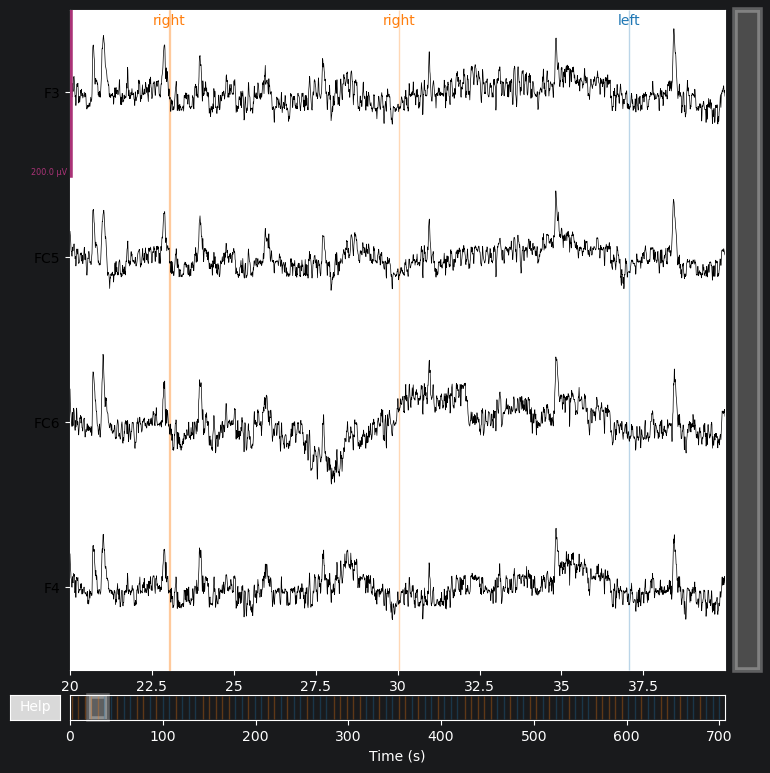

In [4]:
start_sec = 20
end_sec = 40

# Use a wider browser so the channel labels remain visible on the left.
mne.viz.set_browser_backend("matplotlib")
plot_channels = [c for c in ["FC5", "FC6", "F3", "F4"] if c in ch_names_raw]

# Keep every trial in the same class the same color.
annotation_colors = {
    description: (
        "tab:blue" if description == "left"
        else "tab:orange" if description == "right"
        else "tab:gray"
    )
    for description in raw.annotations.description
    if description in {"left", "right"}
}

fig = raw.plot(
    start=start_sec,
    duration=end_sec - start_sec,
    picks=plot_channels,
    n_channels=len(plot_channels),
    scalings=dict(eeg=100e-6),
    annotation_colors=annotation_colors,
)
plt.show()

### Channel Locations (Montage)

So far MNE only knows channel *names*, not where they sit on the scalp. A **montage**
attaches 3-D sensor coordinates to each name, which unlocks topographic (scalp-map)
plotting. All 14 EPOC X channel names are standard 10-20 labels, so MNE's built-in
`standard_1020` montage covers them directly — no manual coordinates needed.

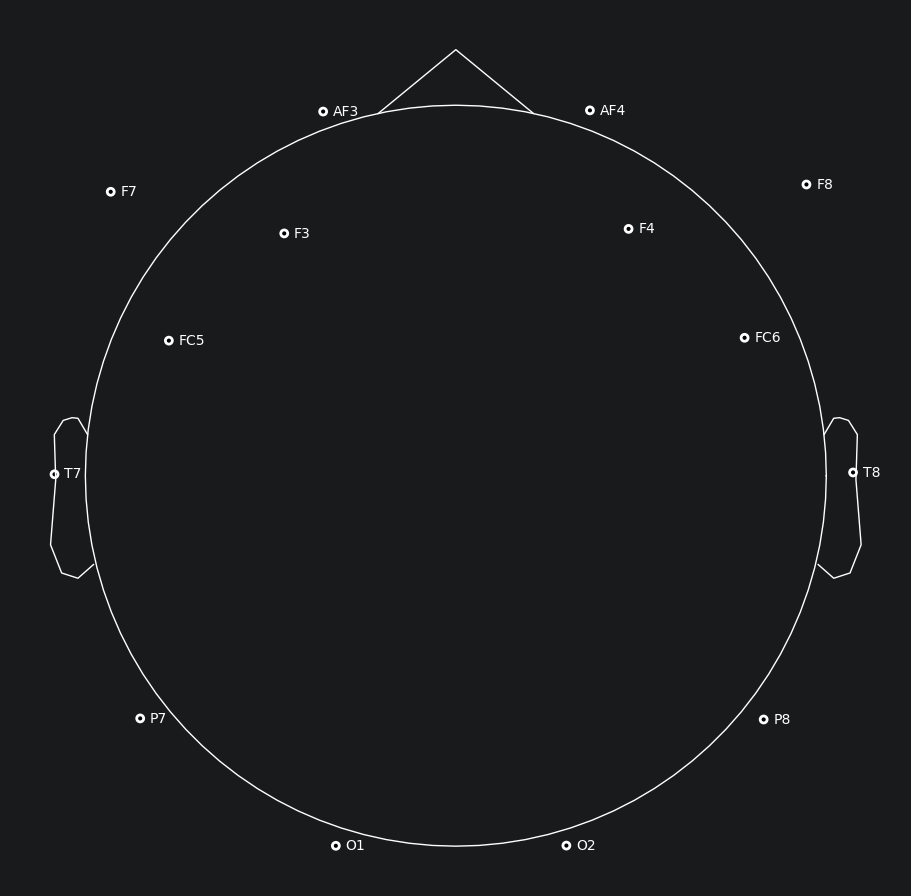

In [5]:
raw.set_montage("standard_1020")
raw.plot_sensors(show_names=True, sphere="auto")
plt.show()

### Power Spectral Density (PSD)

The time-domain plot tells us little about *which* frequencies dominate. `compute_psd()`
runs Welch's method per channel and `.plot()` overlays them. Expect a strong low-frequency
slope (1/f-like) and — since we haven't notch-filtered yet — a spike at **50 Hz** (Tokyo mains
frequency) and its harmonic near 100 Hz.

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


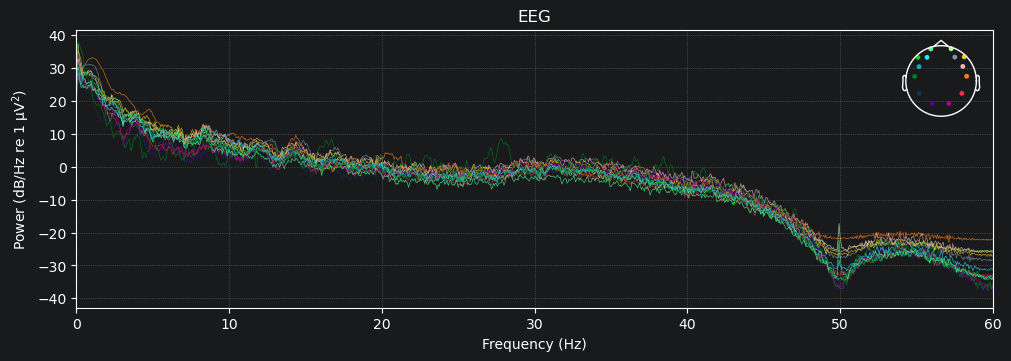

In [6]:
spectrum = raw.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

## 2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch

Section 1 concatenated all sessions into one continuous `raw`. We preprocess that
concatenated Raw directly. MNE inserts `BAD boundary` annotations between sessions, and
`reject_by_annotation=True` excludes any epoch that would cross a session boundary.

We apply, in order:
1. **`raw.notch_filter()`** — remove the 50 Hz mains-power spike (and its harmonics)
2. **`raw.filter()`** — bandpass to the μ/β range where ERD lives
3. **`raw.set_eeg_reference("average")`** — Common Average Reference (CAR), optional
4. **`mne.events_from_annotations()` + `mne.Epochs`** — cut out each 4-second MI trial

### 2-1. Preprocess (notch, bandpass and CAR)

In [7]:
# === Preprocessing controls ===
# BANDPASS_HZ = (low, high): keep EEG frequencies between low and high Hz.
# Examples: (8.0, 30.0) for mu + beta, or (8.0, 13.0) for mu only.
BANDPASS_HZ = (8.0, 30.0)

# NOTCH_HZ: remove electrical mains noise at this frequency.
# Use 50.0 in Japan/Europe, 60.0 in North America, or None to disable it.
NOTCH_HZ = 50.0

# APPLY_CAR: True applies Common Average Reference across all EEG channels.
# Set it to False to keep the original channel references.
APPLY_CAR = True

In [8]:
eeg = raw.copy()

# remove line noise
if NOTCH_HZ is not None:
    eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")

# bandpass filter EEG
eeg.filter(l_freq=BANDPASS_HZ[0], h_freq=BANDPASS_HZ[1], picks="eeg")

# apply common average reference
if APPLY_CAR:
    eeg.set_eeg_reference("average")

Let's check the effect of filtering and CAR on the raw signal with PSD.

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


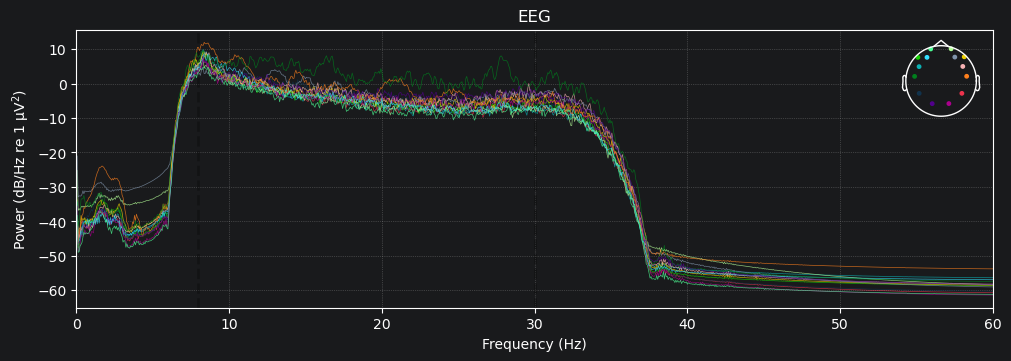

In [9]:
# Power Spectral Density (PSD)
spectrum = eeg.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

### 2-2. Epoch (cut out trials)

#### Extract and inspect events

- Convert the trial annotations into Left and Right event IDs, then plot their timing across the recording.

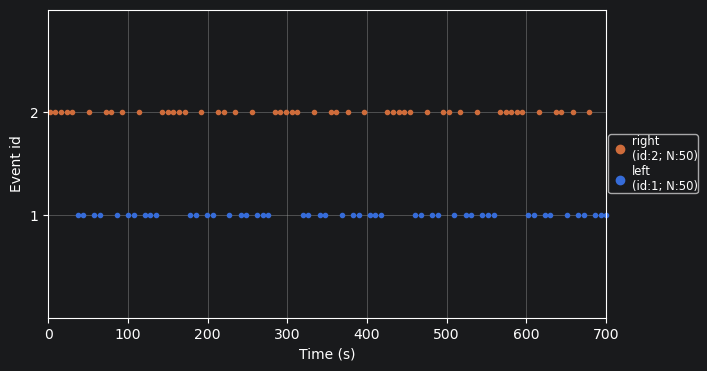

In [10]:
event_dict = {"left": 1, "right": 2}
events, _ = mne.events_from_annotations(eeg, event_id=event_dict)

# Plot the timing and class of all detected trials.
mne.viz.plot_events(
    events,
    sfreq=eeg.info["sfreq"],
    first_samp=eeg.first_samp,
    event_id=event_dict,
)
plt.show()

#### Create epochs

- Extract each trial from **−3 to +4 seconds** relative to MI onset.

- Keep the **−3 to 0 second** pre-task interval for inspection and ERDS, but do not apply
  baseline correction here; CSP/ML uses raw band-power variance.

In [11]:
# Extract 7-second trials: 3 s before to 4 s after MI onset.
# Do not baseline-correct these epochs; CSP/ML works on band-power variance.
epochs = mne.Epochs(
    eeg,
    events,
    event_id=event_dict,
    tmin=-3.0,
    tmax=4.0,
    baseline=None,
    picks="eeg",
    preload=True,
    reject_by_annotation=True,
)

# Epochs crossing session boundaries are rejected automatically.
epochs

<Epochs | 99 events (all good), -3 – 4 s (baseline off), ~9.5 MiB, data loaded,
 'left': 50
 'right': 49>

## 3. Inspect Preprocessed Signals and Reject Bad Trials

The recording has 14 EPOC X channels. The figure below maps the headset channel names to
the brain regions underneath.

| EPOC X channel locations | Motor cortex location |
|---|---|
| ![EPOC X channel placement](assets/epoc_channel_locations.png) | ![Motor cortex region](assets/motor_cortex_regions.png) |

_Source: [channel locations](https://www.researchgate.net/figure/Emotiv-EPOC-headset-14-channel-placement-with-two-reference-channels_fig2_309427804) · [motor cortex](https://www.researchgate.net/figure/Primary-brain-regions-Motor-cortex-is-the-region-in-charge-of-planning-control-and_fig2_331905251)._

Inspect every channel in each trial and record trials containing large artifacts or unstable signals.

### Inspect one trial

Set `trial` to an epoch index (starting from 0). Set `channels` to a list of channel names to limit the display, or `None` to display all EEG channels. The red vertical line marks the motor-imagery onset at 0 s.

Trial index: 4


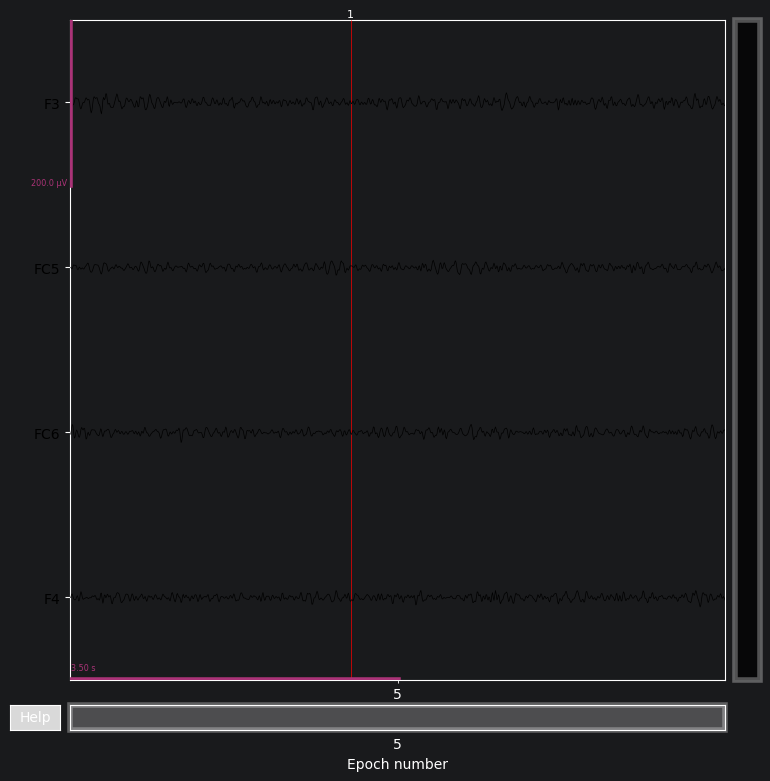

In [12]:
trial = 4
# channels = None  # e.g. ["FC5", "FC6", "F3", "F4"]
channels = ["FC5", "FC6", "F3", "F4"]

selected_channels = epochs.ch_names if channels is None else channels
print(f"Trial index: {trial}")
epochs[trial].plot(
    n_epochs=1,
    picks=selected_channels,
    n_channels=len(selected_channels),
    scalings={"eeg": 100e-6},
    events=True,
    event_color="red",
)
plt.show()

### Mark bad trials

Add the indices of visually contaminated trials to `bad_trial_list`.

In [13]:
# Example: bad_trial_list = [3, 18, 42]
bad_trial_list = []
print(f"Bad trials: {bad_trial_list}")

Bad trials: []


### Remove bad trials

Create a cleaned copy after removing the selected trials.

In [14]:
epochs_clean = epochs.copy()
epochs_clean.drop(bad_trial_list, reason="USER")

print(f"Before: {len(epochs)} trials")
print(f"After : {len(epochs_clean)} trials")

Before: 99 trials
After : 99 trials


## 4. Compute and visualize ERDS maps

An **ERDS map** shows power at every frequency and time point relative to baseline, revealing
*which* frequencies carry the effect and *when* — cool colors mark **ERD** (power drop), warm
mark **ERS** (power increase).

Following MNE's
[ERDS maps example](https://mne.tools/stable/auto_examples/time_frequency/time_frequency_erds.html):
multitaper TFR → percent-baseline normalization → cluster-based permutation test for
significance.

### 4-1. Broadband epochs for the time-frequency decomposition

`epochs_clean` is band-passed to 8–30 Hz (Section 2), which would hide activity outside that
range here. We re-epoch from unfiltered `raw` with just notch + CAR, on **FC5**/**FC6** (the
nearest electrodes to C3/C4).

We pad ±0.5 s onto the −3…4 s window to keep TFR edge effects out of the analysis range, then
crop it back off after computing the TFR. `baseline=None` since normalization happens on the
power spectrum below.

In [15]:
ERDS_CHANNELS = ["FC5", "FC6"]
erds_pad_s = 0.5

eeg_broadband = raw.copy()
if NOTCH_HZ is not None:
    eeg_broadband.notch_filter(freqs=NOTCH_HZ, picks="eeg")
if APPLY_CAR:
    eeg_broadband.set_eeg_reference("average")

epochs_erds = mne.Epochs(
    eeg_broadband,
    events,
    event_id=event_dict,
    tmin=-3.0 - erds_pad_s,
    tmax=4.0 + erds_pad_s,
    baseline=None,
    picks=ERDS_CHANNELS,
    preload=True,
    reject_by_annotation=True,
)
epochs_erds.drop(bad_trial_list, reason="USER")
print(f"ERDS epochs: {len(epochs_erds)} trials, channels={epochs_erds.ch_names}")

ERDS epochs: 99 trials, channels=['FC5', 'FC6']


### 4-2. Multitaper time-frequency decomposition and baseline normalization

- `freqs = 2–35 Hz`, covering θ/μ/β (fs = 128 Hz, well under Nyquist).
- `compute_tfr(average=False)` keeps every trial for the cluster test below.
- `apply_baseline(mode="percent")` normalizes each bin against the −3…0 s baseline — the
  ERDS formula above.

In [16]:
freqs = np.arange(2, 36)
baseline_erds = (-3.0, 0.0)

tfr = epochs_erds.compute_tfr(
    method="multitaper",
    freqs=freqs,
    n_cycles=freqs,
    use_fft=True,
    return_itc=False,
    average=False,
    decim=2,
)
tfr.crop(-3.0, 4.0).apply_baseline(baseline_erds, mode="percent")
print(f"TFR shape (trials, channels, freqs, times): {tfr.data.shape}")

TFR shape (trials, channels, freqs, times): (99, 2, 34, 449)


### 4-3. ERDS maps per condition

`permutation_cluster_1samp_test` runs separately for **ERS** (`tail=1`) and **ERD**
(`tail=-1`); bins with cluster p ≤ 0.05 become the significance mask drawn on the map.
`TwoSlopeNorm` centers the colormap at 0 so ERD and ERS get equal visual weight.

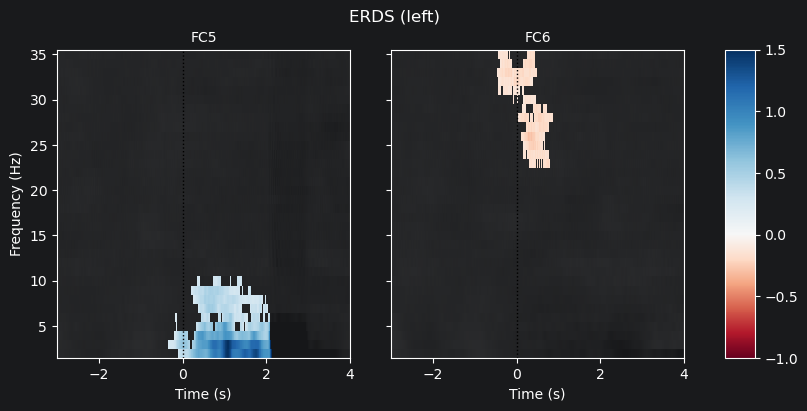

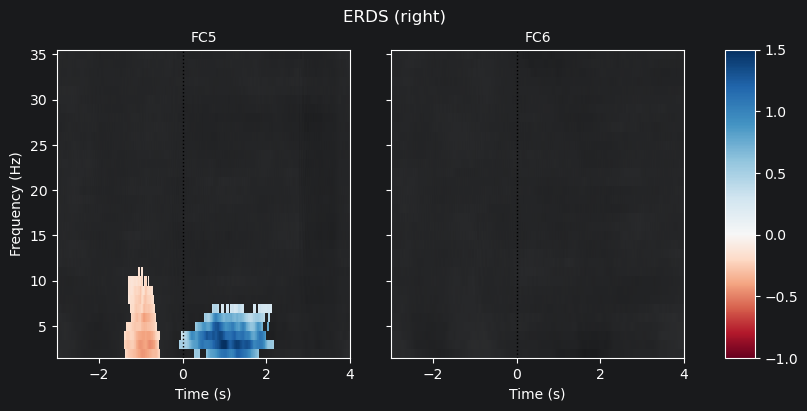

In [17]:
vmin, vmax = -1, 1.5
cnorm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cluster_kwargs = dict(n_permutations=100, step_down_p=0.05, seed=1, buffer_size=None, out_type="mask")

for condition in event_dict:
    tfr_ev = tfr[condition]
    fig, axes = plt.subplots(
        1, len(ERDS_CHANNELS) + 1, figsize=(4 * len(ERDS_CHANNELS) + 1, 4),
        gridspec_kw={"width_ratios": [10] * len(ERDS_CHANNELS) + [1]},
    )
    for ch, ax in enumerate(axes[:-1]):
        _, c1, p1, _ = pcluster_test(tfr_ev.data[:, ch], tail=1, **cluster_kwargs)
        _, c2, p2, _ = pcluster_test(tfr_ev.data[:, ch], tail=-1, **cluster_kwargs)

        c = np.stack(c1 + c2, axis=2)
        p = np.concatenate((p1, p2))
        mask = c[..., p <= 0.05].any(axis=-1)

        tfr_ev.average().plot(
            [ch],
            cmap="RdBu",
            cnorm=cnorm,
            axes=ax,
            colorbar=False,
            show=False,
            mask=mask,
            mask_style="mask",
        )
        ax.set_title(ERDS_CHANNELS[ch], fontsize=10)
        ax.axvline(0, linewidth=1, color="black", linestyle=":")
        if ch != 0:
            ax.set_ylabel("")
            ax.set_yticklabels([])
    fig.colorbar(axes[0].images[-1], cax=axes[-1]).ax.set_yscale("linear")
    fig.suptitle(f"ERDS ({condition})")
    plt.show()

### 4-4. Time course by frequency band

The heatmaps show *where* an effect sits in time and frequency; exporting to a long-format
DataFrame lets us instead compare conditions with confidence bands, averaged per band
(θ/μ/β) and channel.

In [ ]:
df = tfr.to_data_frame(time_format=None, long_format=True)

# Match the definitions above: theta 4–7 Hz, mu 8–13 Hz, beta 14–30 Hz.
band_ranges = {"theta": (4, 7), "mu": (8, 13), "beta": (14, 30)}
df["band"] = pd.Categorical(
    np.select(
        [df["freq"].between(low, high) for low, high in band_ranges.values()],
        list(band_ranges),
        default=None,
    ),
    categories=list(band_ranges),
    ordered=True,
)
df = df.dropna(subset=["band"])
df["channel"] = df["channel"].cat.reorder_categories(ERDS_CHANNELS, ordered=True)

g = sns.FacetGrid(df, row="band", col="channel", margin_titles=True)
g.map(sns.lineplot, "time", "value", "condition", n_boot=10)
axline_kw = dict(color="black", linestyle="dashed", linewidth=0.5, alpha=0.5)
g.map(plt.axhline, y=0, **axline_kw)
g.map(plt.axvline, x=0, **axline_kw)
g.set(ylim=(None, vmax))
g.set_axis_labels("Time (s)", "ERDS")
g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.add_legend(ncol=2, loc="lower center")
g.fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.08)
plt.show()

## 5. CSP (Common Spatial Patterns)

CSP learns a spatial filter — a weighted mix of channels — that **maximizes variance for one
class and minimizes it for the other**. Since band-passed variance equals band power, CSP
builds "composite channels" with the largest left–right power difference. See MNE's
[`CSP` reference](https://mne.tools/stable/generated/mne.decoding.CSP.html) for the full API.

We fit CSP on the MI window only (0–4 s; the −3–0 s segment is baseline, not signal) and draw
its spatial patterns on a scalp map (stronger red/blue = higher electrode contribution).

> **Note:** this visualization CSP uses all data. In cross-validation (Section 6), CSP is
> re-fit per fold on training data only, to avoid leakage.

In [ ]:
# CSP looks for spatial filters that maximize variance (= band power) for one
# class while minimizing it for the other, so it should only see the task window —
# fit it on 0-4 s (MI) and leave out -3-0 s (baseline, no task-related variance).
epochs_mi = epochs_clean.copy().crop(tmin=0.0, tmax=4.0)
X = epochs_mi.get_data(picks="eeg")   # (n_trials, n_channels, n_samples)
y = epochs_mi.events[:, -1] - 1       # mne event ids 1/2 (left/right) -> 0/1

# CAR makes every channel sum to zero, so the spatial covariance is
# rank-deficient (true rank = n_channels - 1). Passing this rank to CSP keeps
# its top component from collapsing onto the empty null direction
# (log-variance ~ -64), which would otherwise make the patterns/features unreadable.
CSP_RANK = {"eeg": X.shape[1] - 1} if APPLY_CAR else None

csp_vis = CSP(n_components=5, reg="ledoit_wolf", log=True, norm_trace=False, rank=CSP_RANK)
csp_vis.fit(X, y)

# Spatial patterns show each component's contribution per electrode.
csp_vis.plot_patterns(epochs_mi.info, components=range(5), ch_type="eeg", units="a.u.", size=1.5)
plt.show()

### CSP Feature Space

Applying CSP to each trial gives a log-power feature per component. The first and last
components are the most discriminative — let's scatter the two classes along them.

In [ ]:
# Log-power feature per component; the first and last are the most discriminative
# (CSP orders components from "class 0 variance max" to "class 1 variance max").
feat = csp_vis.transform(X)  # (n_trials, n_components)
last = csp_vis.n_components - 1

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    mask = y == label
    ax.scatter(feat[mask, 0], feat[mask, last], c=color, label=U.LABEL_NAMES[label], alpha=0.7)
ax.set(xlabel="CSP Component 0 (log-var)", ylabel=f"CSP Component {last} (log-var)",
       title="Class Distribution in CSP Feature Space")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Decoding — Train and Evaluate Classifiers

Sections 4–5 *showed* the left–right difference (ERD maps, CSP patterns). Now we test whether
a model can actually **predict** the imagined side on trials it has never seen.

With only ~95 trials there is no room for a separate test set, so we use **5-fold
cross-validation**: the data is split into 5 parts, each part is predicted once by a model
trained on the other four, and we pool those held-out predictions. Every trial thus gets
exactly one *honest* prediction from a model that never saw it.

**All three** models below use the **same folds**, which lets us (a) compare them fairly
and (b) ask whether they fail on the *same* trials. We report three metrics throughout:

| Metric | What it measures | Chance |
|---|---|---|
| **Accuracy** | fraction of trials predicted correctly | 0.50 |
| **Balanced Accuracy** | mean of per-class recall — unaffected by class imbalance | 0.50 |
| **Cohen's κ** | agreement corrected for chance (1 = perfect, 0 = chance) | 0.00 |

> On a dataset this small, expect modest and *noisy* numbers. A single run slightly above
> chance is not yet proof of decoding — that honesty is part of the lesson.

In [ ]:
# === Channel selection for decoding (applies to BOTH models) ===
# None        -> use every EEG channel (the full montage, as in Section 5).
# ["FC5", ...] -> restrict both models to these channels only. Handy for asking
#                "how much do the sensorimotor channels alone carry?", e.g.
#                ["FC5", "FC6", "F3", "F4"] (the EPOC X has no C3/C4). Pick >= 2.
DECODE_CHANNELS = None

decode_picks = "eeg" if DECODE_CHANNELS is None else DECODE_CHANNELS

# Rebuild the CSP feature matrix on the selected channels. epochs_mi (the 0-4 s MI
# window) and the labels y come from Section 5; y is unaffected by the channel choice.
X = epochs_mi.get_data(picks=decode_picks)
n_selected = X.shape[1]
n_eeg_total = len(mne.pick_types(epochs_mi.info, eeg=True))

# CSP outputs at most one component per channel, so cap the count for narrow selections.
N_CSP = min(4, n_selected)

# CAR (Section 2) makes the FULL channel set sum to zero -> covariance rank
# (n_channels - 1). That deficiency exists ONLY when we keep every channel; any proper
# subset of CAR'd channels is full rank again, so we pass the correct rank to CSP.
CSP_RANK = {"eeg": n_selected - 1} if (APPLY_CAR and n_selected == n_eeg_total) else None

print(f"Decoding on {n_selected} channel(s): "
      f"{epochs_mi.copy().pick(decode_picks).ch_names}")

# Give every trial a stable ID = its row index, so we can report *which* trials each
# model gets wrong and later compare the models trial-by-trial.
trial_ids = np.arange(len(y))

# One fixed set of folds, shared by BOTH models. Stratified => each fold keeps the
# left/right balance; shuffle+seed => reproducible. Every trial lands in exactly one
# test fold, so we get one held-out prediction per trial.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(skf.split(X, y))


def evaluate(name, y_true, y_pred):
    """Print and return the three metrics shared across all models."""
    scores = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
    }
    print(f"{name:10s} | acc={scores['accuracy']:.3f}"
          f" | balanced acc={scores['balanced_accuracy']:.3f}"
          f" | Cohen's κ={scores['cohen_kappa']:+.3f}")
    return scores


def misclassified(y_true, y_pred):
    """Table of the trials a model got wrong, labelled by trial ID."""
    wrong = np.where(y_true != y_pred)[0]
    return pd.DataFrame({
        "trial_id": trial_ids[wrong],
        "true": [U.LABEL_NAMES[c] for c in y_true[wrong]],
        "predicted": [U.LABEL_NAMES[c] for c in y_pred[wrong]],
    })


print(f"{len(y)} trials · {len(folds)} folds "
      f"(test-set sizes: {[len(te) for _, te in folds]})")

### 6-1 CSP + LDA

The classical baseline: **CSP** builds spatial filters that maximize the left–right band-power
difference (Section 5), and a **Linear Discriminant Analysis (LDA)** classifier draws a straight
boundary in that feature space. Both live in one scikit-learn `Pipeline`, so CSP is re-fit on the
training trials **inside every fold** — no test-set leakage.

#### 6-1-1 Evaluate the model

In [ ]:
# CSP sits INSIDE the pipeline, so cross_val_predict re-fits it on each fold's training
# trials only (unlike the whole-data CSP we drew in Section 5).
csp_lda = Pipeline([
    ("csp", CSP(n_components=N_CSP, reg="ledoit_wolf", log=True, rank=CSP_RANK)),
    ("clf", LDA()),
])

# One held-out prediction per trial (from the fold where it was the test set), so
# predictions stay aligned with trial_ids.
y_pred_csp = cross_val_predict(csp_lda, X, y, cv=folds)
scores_csp = evaluate("CSP + LDA", y, y_pred_csp)

#### 6-1-2 Analysis

Two questions: *which* trials does the model miss, and *where* do those errors sit in the CSP
feature space? Listing the misclassified **trial IDs** lets us cross-check them against the deep
networks later; plotting them shows that errors cluster where the two classes overlap.

In [ ]:
mis_csp = misclassified(y, y_pred_csp)
print(f"CSP + LDA misclassified {len(mis_csp)} / {len(y)} trials")
print(mis_csp.to_string(index=False))

In [ ]:
# Fit a CSP on all trials (selected channels) purely to visualize the 2-D feature space
# the decoder works in — same idea as Section 5, but honouring DECODE_CHANNELS. Colour by
# TRUE class and ring the trials the cross-validated model got wrong; errors cluster where
# the two clouds overlap, exactly where a straight boundary cannot separate them.
csp_view = CSP(n_components=N_CSP, reg="ledoit_wolf", log=True, rank=CSP_RANK)
feat = csp_view.fit_transform(X, y)
last = N_CSP - 1
wrong = y_pred_csp != y

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    m = y == label
    ax.scatter(feat[m, 0], feat[m, last], c=color, alpha=0.6, label=U.LABEL_NAMES[label])
ax.scatter(feat[wrong, 0], feat[wrong, last], s=140, facecolors="none",
           edgecolors="k", linewidths=1.5, label="misclassified")
ax.set(xlabel="CSP Component 0 (log-var)", ylabel=f"CSP Component {last} (log-var)",
       title="CSP feature space — misclassified trials ringed")
ax.legend()
plt.tight_layout()
plt.show()

### 6-2 Deep Learning

Instead of hand-crafting spatial filters like CSP, deep networks learn their filters
**end-to-end** from the signal. We try two compact architectures built for EEG, both from
[`braindecode`](https://braindecode.org/) and both wrapped in a scikit-learn–style
`EEGClassifier`:

- **6-2-1 EEGNet** — a small convolutional net: temporal (frequency-selective) filters
  followed by depthwise spatial (CSP-like) filters.
- **6-2-2 EEG-Conformer** — the same convolutional front-end plus a **Transformer**
  self-attention stage, letting it weigh *when* in the trial the informative rhythms appear.

Because both networks learn their own filtering, we give them **different preprocessing** from
CSP: a wider **1–40 Hz** band and **no CAR** (see the code comments for why). The trials stay
aligned with the CSP path, so the shared folds and trial IDs still apply — and we run **both**
nets through the *same* cross-validation loop and the *same* analysis, defined once below.

In [ ]:
# --- Deep-learning stack (installed in the Setup cell on Colab) ---
import torch
from braindecode import EEGClassifier
from braindecode.models import EEGNet, EEGConformer
from skorch.helper import predefined_split
from skorch.dataset import Dataset
from skorch.callbacks import LRScheduler

# Train on GPU when available (Colab: CUDA), else Apple MPS, else CPU.
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Training device:", device)

# BOTH networks share ONE preprocessing, deliberately different from the CSP path:
#   • wider band (1-40 Hz): the networks learn which rhythms matter, so we don't
#     pre-restrict them to mu/beta the way CSP benefits from.
#   • NO Common Average Reference: they learn their own spatial filters, and CAR
#     would spend one spatial degree of freedom before training even starts.
# We align trials to the CSP path by each event's sample position and class ID before
# cropping or selecting channels. This guarantees that rows, folds, and trial IDs match.
DL_BAND = (1.0, 40.0)

eeg_bb = raw.copy()
if NOTCH_HZ is not None:
    eeg_bb.notch_filter(freqs=NOTCH_HZ, picks="eeg")
eeg_bb.filter(l_freq=DL_BAND[0], h_freq=DL_BAND[1], picks="eeg")

epochs_bb = mne.Epochs(eeg_bb, events, event_id=event_dict, tmin=-3.0, tmax=4.0,
                       baseline=None, picks="eeg", preload=True,
                       reject_by_annotation=True)

# Select and reorder broadband epochs by the exact CSP event identity. This also removes
# the same manually rejected trials without assuming interchangeable row indices.
bb_event_index = {tuple(event): i for i, event in enumerate(epochs_bb.events)}
csp_event_keys = [tuple(event) for event in epochs_mi.events]
if len(bb_event_index) != len(epochs_bb.events):
    raise RuntimeError("Duplicate event identities prevent unambiguous trial alignment.")
missing_events = [event for event in csp_event_keys if event not in bb_event_index]
if missing_events:
    raise RuntimeError(f"Broadband path is missing CSP events: {missing_events}")
epochs_bb = epochs_bb[[bb_event_index[event] for event in csp_event_keys]]
epochs_bb.crop(tmin=0.0, tmax=4.0)

# braindecode expects float32 (trials, channels, samples). Convert volts -> microvolts
# (a fixed scale, no train/test leakage); the networks' internal BatchNorm handles the rest.
X_net = epochs_bb.get_data(picks=decode_picks).astype("float32") * 1e6
y_net = epochs_bb.events[:, -1] - 1
assert np.array_equal(epochs_bb.events, epochs_mi.events)
assert np.array_equal(y_net, y)

n_chans, n_times = X_net.shape[1], X_net.shape[2]
print(f"Network input: {X_net.shape}  ({n_chans} channels x {n_times} samples)")

In [ ]:
# Both networks train the same way — a fresh model per fold, with each fold's held-out
# trials used as the validation set — and both get the same three-view analysis. We write
# that ONCE here and reuse it, so the EEGNet and Conformer sections differ only in the model.
N_EPOCHS = 50
BATCH_SIZE = 16
LEARNING_RATE = 1e-4


def train_cv_dl(model_cls, model_name, n_epochs=N_EPOCHS, **module_kwargs):
    """5-fold CV for any braindecode model. Returns (y_pred, scores, histories).

    A fresh network is trained on each fold's training trials and predicts its held-out
    trials; those held-out trials are also passed as skorch's validation set, so the
    recorded ``valid_loss`` is exactly the generalization loss we plot in the analysis.
    Extra ``module_kwargs`` (e.g. ``module__final_fc_length="auto"``) go straight to the model.
    """
    y_pred = np.empty(len(y_net), dtype=int)
    histories = []  # one learning history per fold
    for k, (train_idx, test_idx) in enumerate(folds):
        torch.manual_seed(0)  # align PyTorch's initial random state across folds
        valid_ds = Dataset(X_net[test_idx], y_net[test_idx])  # held-out = validation set
        net = EEGClassifier(
            model_cls,
            module__n_chans=n_chans,
            module__n_outputs=2,
            module__n_times=n_times,
            **module_kwargs,
            optimizer=torch.optim.Adam,
            lr=LEARNING_RATE,
            max_epochs=n_epochs,
            batch_size=BATCH_SIZE,
            train_split=predefined_split(valid_ds),
            callbacks=[("lr", LRScheduler("CosineAnnealingLR", T_max=n_epochs - 1))],
            device=device,
            verbose=0,
        )
        net.fit(X_net[train_idx], y_net[train_idx])
        y_pred[test_idx] = net.predict(X_net[test_idx])
        histories.append(net.history)
        print(f"  fold {k}: train_loss={net.history[-1, 'train_loss']:.3f}"
              f"  valid_loss={net.history[-1, 'valid_loss']:.3f}")
    scores = evaluate(model_name, y, y_pred)
    return y_pred, scores, histories


def analyze_dl(model_name, y_pred, scores, histories):
    """Three views of a trained model: learning curves, confusion matrix, missed trials."""
    # 1) Learning curves — one panel per fold. Training loss should fall steadily; a
    #    validation loss that flattens or climbs while training loss keeps dropping is the
    #    classic signature of OVERFITTING (expected here — ~95 trials is tiny for a net).
    fig, axes = plt.subplots(1, len(histories), figsize=(16, 3), sharey=True)
    for k, (ax, h) in enumerate(zip(axes, histories)):
        ax.plot(h[:, "epoch"], h[:, "train_loss"], label="train")
        ax.plot(h[:, "epoch"], h[:, "valid_loss"], label="valid")
        ax.set(title=f"Fold {k}", xlabel="epoch")
    axes[0].set_ylabel("loss")
    axes[0].legend()
    fig.suptitle(f"{model_name} learning curves (one per cross-validation fold)")
    plt.tight_layout()
    plt.show()

    # 2) Overall confusion matrix, pooled over every fold's held-out predictions.
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=[U.LABEL_NAMES[0], U.LABEL_NAMES[1]])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} — overall confusion matrix "
              f"(acc={scores['accuracy']:.2f}, κ={scores['cohen_kappa']:+.2f})")
    plt.tight_layout()
    plt.show()

    # 3) Which trials it missed — for a trial-by-trial comparison across models.
    mis = misclassified(y, y_pred)
    print(f"{model_name} misclassified {len(mis)} / {len(y)} trials")
    print(mis.to_string(index=False))
    return mis

#### 6-2-1 EEGNet

**EEGNet** is a compact convolutional network designed for EEG: a first layer of temporal
convolutions learns frequency-selective filters, and a depthwise spatial convolution learns
CSP-like spatial filters — end-to-end, with only a few thousand parameters.

##### 6-2-1-1 Evaluate the model

We run EEGNet through the shared 5-fold loop: a fresh net per fold, predicting its held-out
trials. On a GPU (Colab: *Runtime > Change runtime type > GPU*) this takes seconds; on CPU, a
minute or two.

In [ ]:
y_pred_net, scores_net, hist_net = train_cv_dl(EEGNet, "EEGNet")

##### 6-2-1-2 Analysis

Three views: the **learning curves** (do the folds learn, or just overfit?), the overall
**confusion matrix**, and the **trial IDs** EEGNet got wrong — kept for the model-vs-model
comparison in 6-3.

In [ ]:
mis_net = analyze_dl("EEGNet", y_pred_net, scores_net, hist_net)

#### 6-2-2 EEG-Conformer

**EEG-Conformer** keeps a convolutional front-end (temporal + spatial filters, like EEGNet) but
then adds a **Transformer**: self-attention lets the model compare *different time segments* of
the trial and weigh where the informative μ/β desynchronization occurs, instead of treating every
moment equally. It has many more parameters than EEGNet, so on ~95 trials expect it to overfit
even harder — a useful contrast to read off the learning curves.

##### 6-2-2-1 Evaluate the model

The same loop and the same folds — only the model class changes. `module__final_fc_length="auto"`
lets braindecode size the classifier head to our trial length automatically.

In [29]:
# Same CV loop as EEGNet; only the architecture differs. 'auto' sizes the Conformer's final
# fully-connected layer to n_times (its convolutional front-end determines the sequence length).
y_pred_conf, scores_conf, hist_conf = train_cv_dl(
    EEGConformer, "Conformer", module__final_fc_length="auto")

  fold 1: train_loss=0.691  valid_loss=0.692
  fold 2: train_loss=0.675  valid_loss=0.697
  fold 3: train_loss=0.657  valid_loss=0.688
  fold 4: train_loss=0.645  valid_loss=0.760
Conformer  | acc=0.515 | balanced acc=0.514 | Cohen's κ=+0.027


##### 6-2-2-2 Analysis

The same three views as EEGNet — read the learning curves for the (likely stronger) overfitting
that comes with the Conformer's larger capacity.

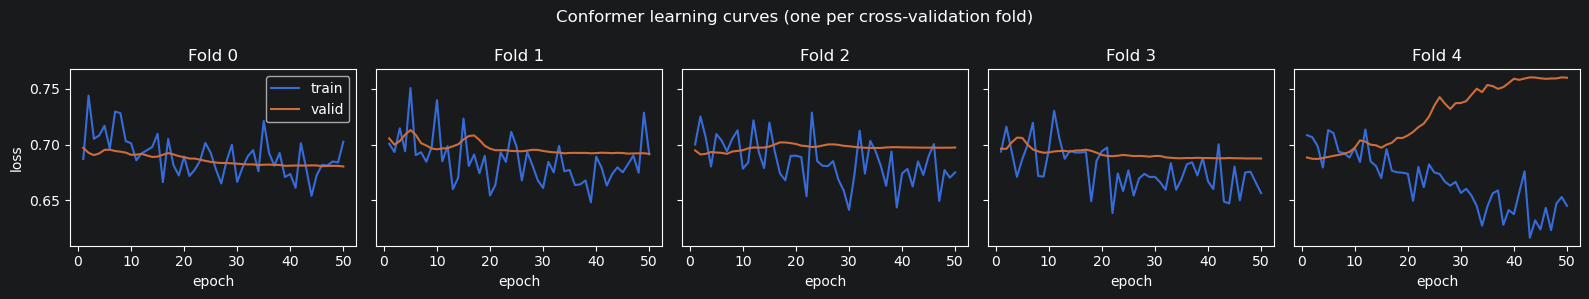

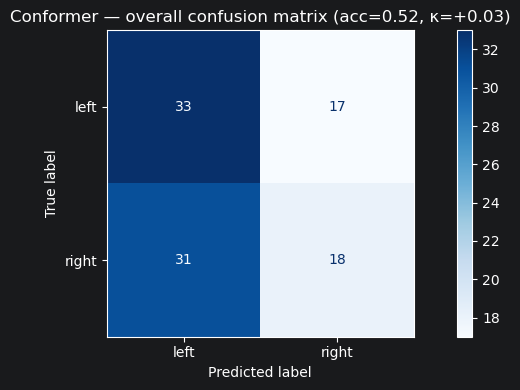

Conformer misclassified 48 / 99 trials
 trial_id  true predicted
        0 right      left
        3 right      left
        4  left     right
        6 right      left
        8  left     right
       11  left     right
       14  left     right
       15 right      left
       17  left     right
       18  left     right
       19 right      left
       20 right      left
       21 right      left
       23 right      left
       26 right      left
       32 right      left
       35 right      left
       39 right      left
       40 right      left
       41 right      left
       43 right      left
       44  left     right
       45  left     right
       47  left     right
       48  left     right
       50 right      left
       52 right      left
       55 right      left
       56  left     right
       57  left     right
       59 right      left
       60 right      left
       61 right      left
       62 right      left
       63 right      left
       67  left     right

In [30]:
mis_conf = analyze_dl("Conformer", y_pred_conf, scores_conf, hist_conf)

### 6-3 Comparison — Classical vs Deep Learning

Finally, the three metrics for all three models side by side. On a dataset of this size, expect
classical **CSP + LDA** to match or beat both networks: deep models are data-hungry, and the loss
curves above show them overfitting before they can generalize — the larger the model, the sooner.
The trials that *every* model misses are the genuinely **hard** ones (noisy recordings or
ambiguous imagery) rather than any single model's weakness.

In [31]:
summary = pd.DataFrame({
    "CSP + LDA": scores_csp,
    "EEGNet": scores_net,
    "Conformer": scores_conf,
}).T
summary.index.name = "model"
print(summary.round(3).to_string())

           accuracy  balanced_accuracy  cohen_kappa
model                                              
CSP + LDA     0.596              0.596        0.191
EEGNet        0.576              0.576        0.151
Conformer     0.515              0.514        0.027
